Enter your Roll Number: 51

Roll Number: 51
Grid Points: 251

EXERCISE 1: GRID REFINEMENT
-----------------------------------------------------------------
N         CFL         Explicit L2         Implicit L2         
100       0.78302     0.01051554          0.03022174          
200       0.79545     0.00581506          0.02363066          
400       0.79545     0.00316086          0.01675056          


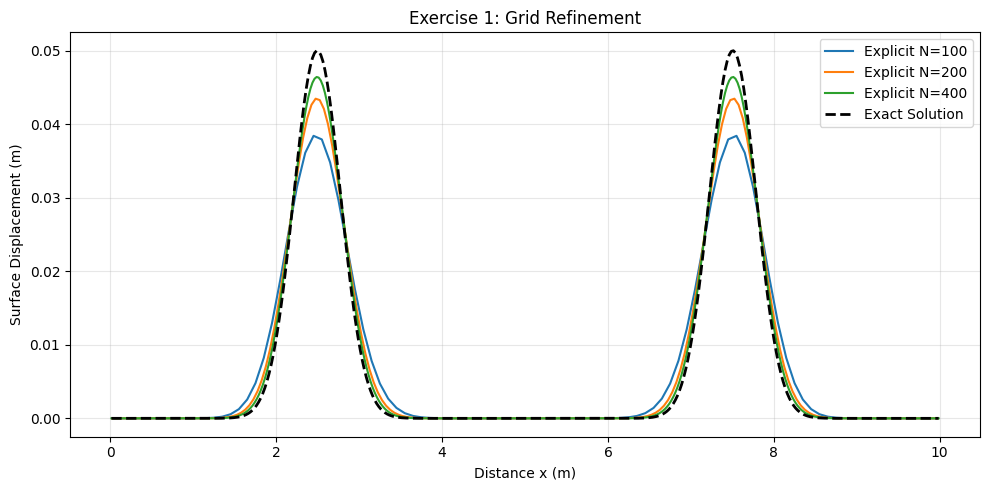


EXERCISE 2: IMPLICIT CFL COMPARISON
-----------------------------------------------------------------
Target CFL=0.8 | Actual CFL=0.79611 | L2 Error=0.02135289 | Peak=0.02786788
Target CFL=0.4 | Actual CFL=0.39805 | L2 Error=0.01885907 | Peak=0.03022118


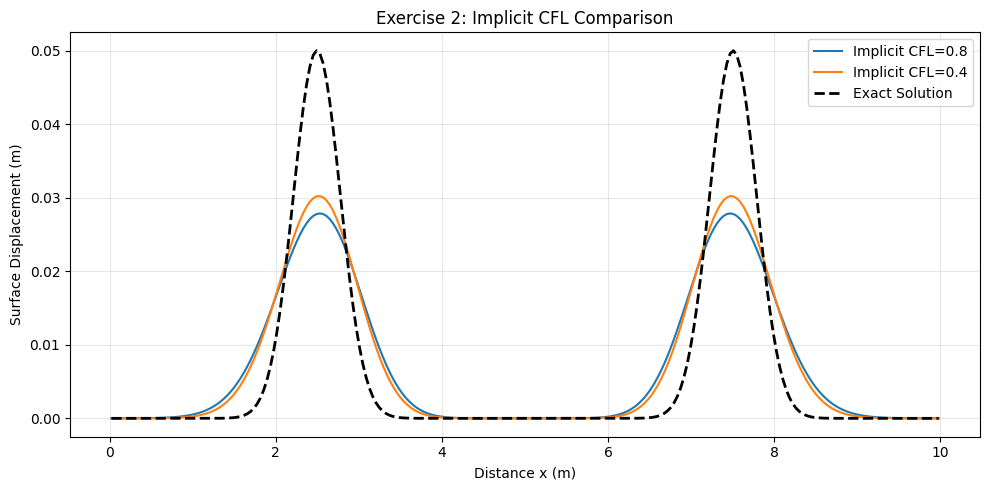


EXERCISE 3: EXPLICIT CFL STABILITY
-----------------------------------------------------------------
Target CFL=0.8 | Actual CFL=0.79611 | Maximum |eta|=4.464121e-02
Target CFL=1.0 | Actual CFL=0.99829 | Maximum |eta|=4.994145e-02
Target CFL=1.2 | Actual CFL=1.18665 | Maximum |eta|=5.687482e-02
Target CFL=1.5 | Actual CFL=1.49744 | Maximum |eta|=7.653374e-02


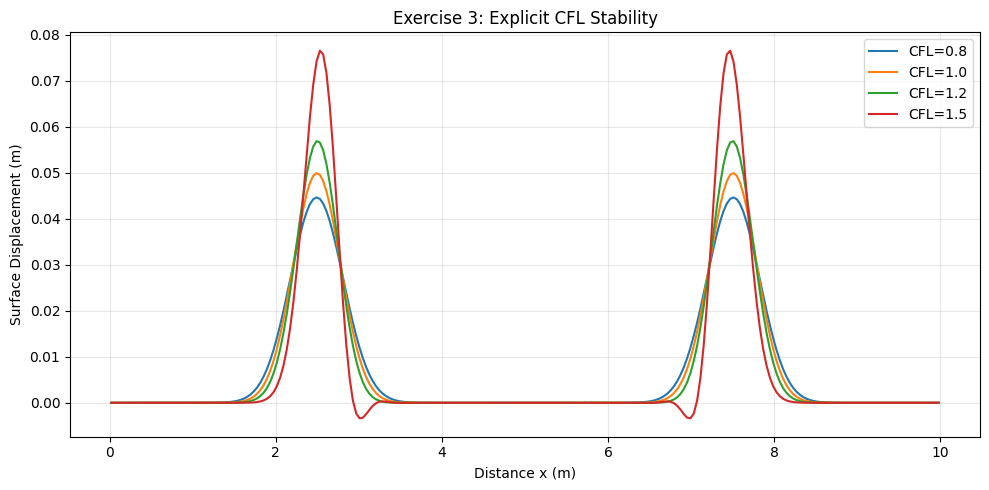


MAIN EXPERIMENT RESULTS
-----------------------------------------------------------------
Roll Number: 51
Grid Points N: 251
Grid Spacing dx: 0.039841 m
Time Step dt: 0.01012658 s
CFL: 0.796106
Wave Speed: 3.132092 m/s
Simulation Time: 0.800 s

VOLUME CONSERVATION
Initial Volume: 0.070898154036
Explicit Volume: 0.070898154036
Implicit Volume: 0.070898154036
Explicit Relative Error: 1.957e-16
Implicit Relative Error: 5.872e-16

L2 ERROR
Explicit L2 Error: 0.00477491
Implicit L2 Error: 0.02135289


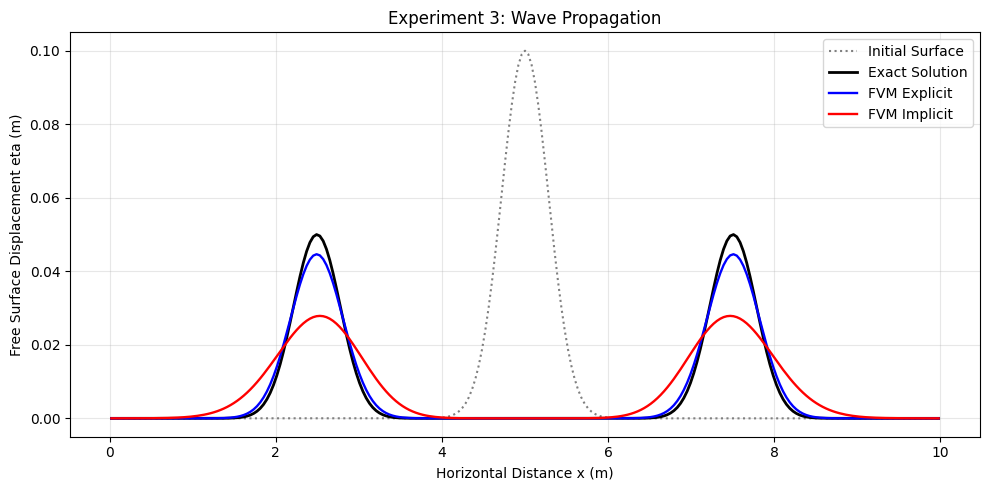


ALL SIMULATIONS COMPLETED SUCCESSFULLY.


In [4]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.sparse import lil_matrix
from scipy.sparse.linalg import factorized

# ============================================
# STUDENT INPUT
# ============================================

roll_no = 20  # Roll number
nx = 200 + roll_no

print("\nRoll Number:", roll_no)
print("Grid Points:", nx)

# ============================================
# COMMON PARAMETERS
# ============================================

L = 10.0
H = 1.0
g = 9.81

A0 = 0.10
width = 0.40
t_end = 0.80

c = np.sqrt(g * H)


# ============================================
# SIMULATION FUNCTION
# ============================================

def run_simulation(nx, target_cfl=0.8, method="both"):

    dx = L / nx

    steps = int(np.ceil(
        t_end * c / (target_cfl * dx)
    ))

    dt = t_end / steps
    lam = c * dt / dx

    x = (np.arange(nx) + 0.5) * dx

    initial = A0 * np.exp(
        -((x - L / 2) / width) ** 2
    )

    r_exp = initial.copy()
    l_exp = initial.copy()
    r_imp = initial.copy()
    l_imp = initial.copy()

    if method in ("implicit", "both"):

        M_r = lil_matrix((nx, nx))
        M_l = lil_matrix((nx, nx))

        for i in range(nx):
            M_r[i, i] = 1 + lam
            M_r[i, (i - 1) % nx] = -lam

            M_l[i, i] = 1 + lam
            M_l[i, (i + 1) % nx] = -lam

        solve_r = factorized(M_r.tocsc())
        solve_l = factorized(M_l.tocsc())

    for _ in range(steps):

        if method in ("explicit", "both"):

            r_exp = r_exp - lam * (
                r_exp - np.roll(r_exp, 1)
            )

            l_exp = l_exp - lam * (
                l_exp - np.roll(l_exp, -1)
            )

        if method in ("implicit", "both"):

            r_imp = solve_r(r_imp)
            l_imp = solve_l(l_imp)

    eta_exp = 0.5 * (r_exp + l_exp)
    eta_imp = 0.5 * (r_imp + l_imp)

    eta_exact = 0.5 * A0 * (
        np.exp(-((x-L/2-c*t_end)/width)**2)
        +
        np.exp(-((x-L/2+c*t_end)/width)**2)
    )

    l2_exp = np.sqrt(
        dx * np.sum((eta_exp - eta_exact)**2)
    )

    l2_imp = np.sqrt(
        dx * np.sum((eta_imp - eta_exact)**2)
    )

    vol_0 = dx * np.sum(initial)
    vol_exp = dx * np.sum(eta_exp)
    vol_imp = dx * np.sum(eta_imp)

    return {
        "x": x,
        "initial": initial,
        "exact": eta_exact,
        "explicit": eta_exp,
        "implicit": eta_imp,
        "l2_exp": l2_exp,
        "l2_imp": l2_imp,
        "vol_0": vol_0,
        "vol_exp": vol_exp,
        "vol_imp": vol_imp,
        "cfl": lam,
        "dt": dt
    }


# ============================================
# EXERCISE 1: GRID REFINEMENT
# N = 100, 200, 400
# ============================================

print("\nEXERCISE 1: GRID REFINEMENT")
print("-" * 65)

print(f"{'N':<10}{'CFL':<12}{'Explicit L2':<20}{'Implicit L2':<20}")

plt.figure(figsize=(10, 5))

for n in [100, 200, 400]:

    res = run_simulation(n, 0.8)

    print(
        f"{n:<10}{res['cfl']:<12.5f}"
        f"{res['l2_exp']:<20.8f}"
        f"{res['l2_imp']:<20.8f}"
    )

    plt.plot(
        res["x"], res["explicit"],
        label=f"Explicit N={n}"
    )

plt.plot(
    res["x"], res["exact"],
    "k--", linewidth=2,
    label="Exact Solution"
)

plt.title("Exercise 1: Grid Refinement")
plt.xlabel("Distance x (m)")
plt.ylabel("Surface Displacement (m)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("exercise_1.png", dpi=180)
plt.show()


# ============================================
# EXERCISE 2: IMPLICIT CFL COMPARISON
# CFL = 0.8 AND 0.4
# ============================================

print("\nEXERCISE 2: IMPLICIT CFL COMPARISON")
print("-" * 65)

plt.figure(figsize=(10, 5))

for target in [0.8, 0.4]:

    res = run_simulation(
        nx, target, method="implicit"
    )

    print(
        f"Target CFL={target} | "
        f"Actual CFL={res['cfl']:.5f} | "
        f"L2 Error={res['l2_imp']:.8f} | "
        f"Peak={np.max(res['implicit']):.8f}"
    )

    plt.plot(
        res["x"], res["implicit"],
        label=f"Implicit CFL={target}"
    )

plt.plot(
    res["x"], res["exact"],
    "k--", linewidth=2,
    label="Exact Solution"
)

plt.title("Exercise 2: Implicit CFL Comparison")
plt.xlabel("Distance x (m)")
plt.ylabel("Surface Displacement (m)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("exercise_2.png", dpi=180)
plt.show()


# ============================================
# EXERCISE 3: EXPLICIT CFL STABILITY
# ============================================

print("\nEXERCISE 3: EXPLICIT CFL STABILITY")
print("-" * 65)

plt.figure(figsize=(10, 5))

for target in [0.8, 1.0, 1.2, 1.5]:

    res = run_simulation(
        nx, target, method="explicit"
    )

    max_eta = np.max(np.abs(res["explicit"]))

    print(
        f"Target CFL={target} | "
        f"Actual CFL={res['cfl']:.5f} | "
        f"Maximum |eta|={max_eta:.6e}"
    )

    if np.all(np.isfinite(res["explicit"])):

        plt.plot(
            res["x"], res["explicit"],
            label=f"CFL={target}"
        )

plt.title("Exercise 3: Explicit CFL Stability")
plt.xlabel("Distance x (m)")
plt.ylabel("Surface Displacement (m)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("exercise_3.png", dpi=180)
plt.show()


# ============================================
# MAIN EXPERIMENT
# ============================================

print("\nMAIN EXPERIMENT RESULTS")
print("-" * 65)

res = run_simulation(nx, 0.8, method="both")

dx = L / nx

print(f"Roll Number: {roll_no}")
print(f"Grid Points N: {nx}")
print(f"Grid Spacing dx: {dx:.6f} m")
print(f"Time Step dt: {res['dt']:.8f} s")
print(f"CFL: {res['cfl']:.6f}")
print(f"Wave Speed: {c:.6f} m/s")
print(f"Simulation Time: {t_end:.3f} s")

print("\nVOLUME CONSERVATION")

print(f"Initial Volume: {res['vol_0']:.12f}")
print(f"Explicit Volume: {res['vol_exp']:.12f}")
print(f"Implicit Volume: {res['vol_imp']:.12f}")

print(
    "Explicit Relative Error:",
    f"{abs(res['vol_exp']-res['vol_0'])/res['vol_0']:.3e}"
)

print(
    "Implicit Relative Error:",
    f"{abs(res['vol_imp']-res['vol_0'])/res['vol_0']:.3e}"
)

print("\nL2 ERROR")

print(f"Explicit L2 Error: {res['l2_exp']:.8f}")
print(f"Implicit L2 Error: {res['l2_imp']:.8f}")


# ============================================
# FINAL GRAPH
# ============================================

plt.figure(figsize=(10, 5))

plt.plot(
    res["x"], res["initial"],
    ":", color="gray",
    linewidth=1.5,
    label="Initial Surface"
)

plt.plot(
    res["x"], res["exact"],
    "k-", linewidth=2,
    label="Exact Solution"
)

plt.plot(
    res["x"], res["explicit"],
    color="blue", linewidth=1.7,
    label="FVM Explicit"
)

plt.plot(
    res["x"], res["implicit"],
    color="red", linewidth=1.7,
    label="FVM Implicit"
)

plt.xlabel("Horizontal Distance x (m)")
plt.ylabel("Free Surface Displacement eta (m)")

plt.title("Experiment 3: Wave Propagation")

plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig(
    "experiment_3_wave_output.png",
    dpi=180
)

plt.show()


# ============================================
# COMPLETION
# ============================================

print("\nALL SIMULATIONS COMPLETED SUCCESSFULLY.")
